# Dictionary 1 on the third LeiData recording

Dictionary 1 (`ten balanced motifs`) has 10 motifs learned on the GPL whitened spectrogram of `SOCAL_H_76_230427_014845.x.wav`. Each motif is five components plus a mean. The columns each motif covers run from 165 to 660, a factor of 4. Every motif's mean residual gap is at least 0.1. Together the placements cover 0.187 of the recording (3425 of 18270 columns).

The score at each time is the matching-pursuit amplitude of that mean:

`alpha(t) = <S[:, t:t+W], A> / ||A||^2`

`S` is the whitened spectrogram, `A` is the mean, and `W` is the motif width in time bins. Columns where the motif would run past the end of the recording are NaN. A column is `0.12288` seconds.


In [1]:
import sqlite3
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().resolve()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / "analysis" / "evaluation" / "core.py").is_file():
        if str(candidate) not in sys.path:
            sys.path.insert(0, str(candidate))
        break

from analysis.GPL_Python.gpl_outputs import display_from_spwhiten
from analysis.dict_learning.code.io import discover_windows
from analysis.evaluation.core import _dot_products, _load_motif, _stitch, _whitened_dir

CATALOG = Path("/home/rivo/production-pmp-webserver/backend/data/catalog.sqlite")
WAV = Path("/home/yfreund/whale_processing/LeiData/SOCAL_H_76_230427_014845.x.wav")
DICTIONARY_ID = 1
NPY = Path(
    "/home/yfreund/whale_processing/result/LeiData/"
    "SOCAL_H_76_230427_014845.x.gpl/output/spectrogram_npy"
)

conn = sqlite3.connect(f"file:{CATALOG}?mode=ro", uri=True)
rows = conn.execute(
    """
    SELECT t.template_id, t.width, t.npy_path
    FROM dictionary_templates dt
    JOIN templates t ON t.template_pk = dt.template_pk
    WHERE dt.dictionary_id = ?
    ORDER BY dt.position
    """,
    (DICTIONARY_ID,),
).fetchall()
conn.close()

spectrogram, offset = _stitch(_whitened_dir(CATALOG, WAV))
windows = discover_windows(NPY)
windows.sort(key=lambda window: (window.start_sample, window.window_id))
sec_per_bin = float(windows[0].overlap) / float(windows[0].sample_freq)
start_freq = float(windows[0].start_freq)
end_freq = float(windows[0].end_freq)

motif_ids = []
widths = []
atoms = []
score_rows = []
for template_id, width, path in rows:
    motif = _load_motif(path)
    energy = float(np.sum(motif * motif))
    motif_ids.append(int(template_id))
    widths.append(int(width))
    atoms.append(motif)
    score_rows.append(_dot_products(spectrogram, motif) / energy)
scores = np.vstack(score_rows)
time_min = np.arange(scores.shape[1]) * sec_per_bin / 60.0

print(
    f"scores {scores.shape}  motifs {motif_ids}  "
    f"bin {sec_per_bin:.5f} s  duration {scores.shape[1] * sec_per_bin / 60:.2f} min"
)
for motif_id, width, row in zip(motif_ids, widths, scores):
    peak = int(np.nanargmax(np.abs(row)))
    print(
        f"motif {motif_id:3d}  width {width} bins ({width * sec_per_bin:.2f} s)  "
        f"peak {row[peak]:.4f} at {time_min[peak]:.2f} min"
    )


scores (10, 18270)  motifs [0, 1, 3, 10, 11, 13, 14, 17, 100, 200]  bin 0.12288 s  duration 37.42 min
motif   0  width 13 bins (1.60 s)  peak 1.9551 at 0.01 min
motif   1  width 10 bins (1.23 s)  peak 2.3591 at 0.38 min
motif   3  width 13 bins (1.60 s)  peak 1.9753 at 0.66 min
motif  10  width 15 bins (1.84 s)  peak 1.4999 at 1.80 min
motif  11  width 14 bins (1.72 s)  peak 2.4320 at 36.95 min
motif  13  width 16 bins (1.97 s)  peak 2.3604 at 37.26 min
motif  14  width 11 bins (1.35 s)  peak 1.7093 at 34.14 min
motif  17  width 18 bins (2.21 s)  peak 1.5646 at 9.59 min
motif 100  width 11 bins (1.35 s)  peak 2.5248 at 0.01 min
motif 200  width 28 bins (3.44 s)  peak 1.6268 at 0.84 min


## Balanced coverage and residual gap

A motif's coverage is the number of spectrogram columns its placements occupy. The gap at a placement is the unexplained fraction of the best other motif minus the unexplained fraction of the motif placed there.


accepted True
recording coverage 0.187  (3425 / 18270 columns)  motifs 10  placements 261
pass  n_motifs = 10
pass  n_components = 5
pass  coverage_ratio = 4.000
pass  min_gap = 0.101


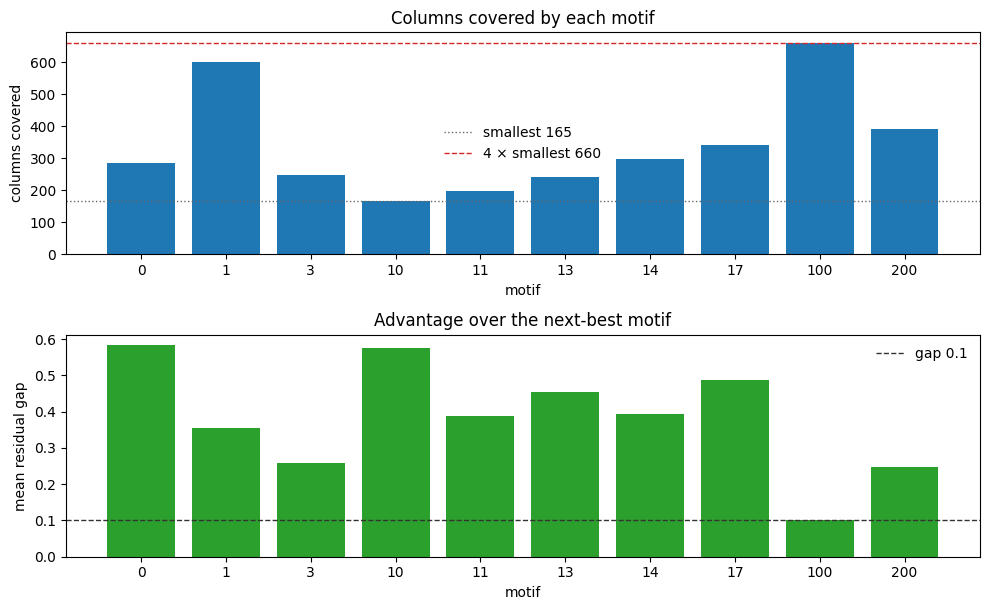

  id      n    cols      gap      own   runner  runner_id
   0     22     286    0.583    0.162    0.744  11
   1     60     600    0.354    0.258    0.611  100
   3     19     247    0.259    0.186    0.445  100
  10     11     165    0.574    0.116    0.691  3
  11     14     196    0.389    0.196    0.585  200
  13     15     240    0.454    0.234    0.688  200
  14     27     297    0.393    0.277    0.669  1
  17     19     342    0.487    0.129    0.616  3
 100     60     660    0.101    0.249    0.350  200
 200     14     392    0.246    0.134    0.380  100


In [2]:
import json

OUT = Path(
    "/home/yfreund/whale_processing/result/LeiData/"
    "SOCAL_H_76_230427_014845.x.limited_overlap_ten_balanced"
)
summary = json.loads((OUT / "summary.json").read_text())
motifs = sorted(summary["motifs"], key=lambda row: row["motif_id"])
print(f"accepted {summary['accepted']}")
print(
    f"recording coverage {summary['coverage']:.3f}  "
    f"({summary['n_bins_covered']} / {summary['n_bins_total']} columns)  "
    f"motifs {summary['n_motifs']}  placements {summary['n_placements']}"
)
for name, check in summary["checks"].items():
    value = check["value"]
    shown = f"{value:.3f}" if isinstance(value, float) else value
    print(f"{'pass' if check['ok'] else 'fail'}  {name} = {shown}")

names = [str(row["motif_id"]) for row in motifs]
covered = [row["n_columns"] for row in motifs]
gaps = [row["mean_gap"] for row in motifs]
smallest = min(covered)
fig, axes = plt.subplots(2, 1, figsize=(10, 6.2))
axes[0].bar(names, covered, color="C0")
axes[0].axhline(smallest, color="0.4", ls=":", lw=1, label=f"smallest {smallest}")
axes[0].axhline(4 * smallest, color="C3", ls="--", lw=1, label=f"4 × smallest {4 * smallest}")
axes[0].set_ylabel("columns covered")
axes[0].set_xlabel("motif")
axes[0].set_title("Columns covered by each motif")
axes[0].legend(frameon=False)
axes[1].bar(names, gaps, color="C2")
axes[1].axhline(0.1, color="0.2", ls="--", lw=1, label="gap 0.1")
axes[1].set_ylabel("mean residual gap")
axes[1].set_xlabel("motif")
axes[1].set_title("Advantage over the next-best motif")
axes[1].legend(frameon=False)
fig.tight_layout()
plt.show()
print(f"{'id':>4}  {'n':>5}  {'cols':>6}  {'gap':>7}  {'own':>7}  {'runner':>7}  runner_id")
for row in motifs:
    print(
        f"{row['motif_id']:4d}  {row['n_placements']:5d}  {row['n_columns']:6d}  {row['mean_gap']:7.3f}  "
        f"{row['mean_own']:7.3f}  {row['mean_runner']:7.3f}  {row['runner_id']}"
    )


## Motif means

Each image is the cube root of the absolute mean, the same display transform as the GPL spectrogram. Time runs left to right and frequency upward. The number on each panel is the motif id.


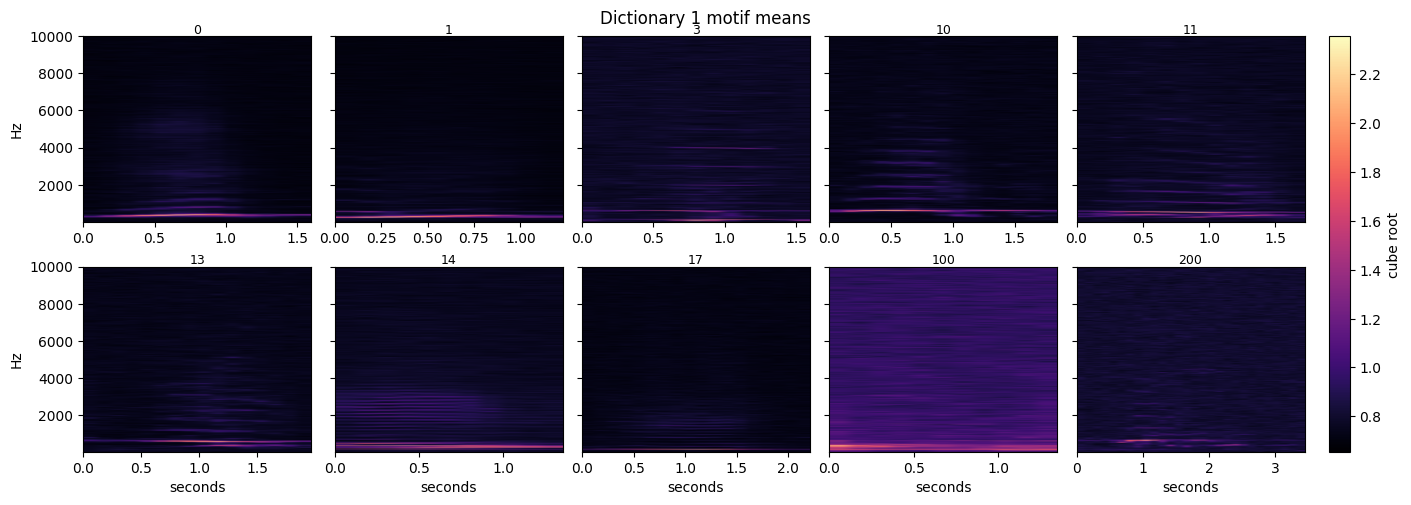

In [3]:
ncols = 5
nrows = int(np.ceil(len(atoms) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 2.4 * nrows), sharey=True, layout="constrained")
axes = np.atleast_2d(axes)
for i, (motif_id, atom) in enumerate(zip(motif_ids, atoms)):
    r, c = divmod(i, ncols)
    ax = axes[r, c]
    shown = display_from_spwhiten(atom)
    extent = [0, atom.shape[1] * sec_per_bin, start_freq, end_freq]
    im = ax.imshow(shown, origin="lower", aspect="auto", cmap="magma", extent=extent)
    ax.set_title(str(motif_id), fontsize=9, pad=2)
    if c == 0:
        ax.set_ylabel("Hz")
    if r == nrows - 1:
        ax.set_xlabel("seconds")
for j in range(len(atoms), nrows * ncols):
    r, c = divmod(j, ncols)
    axes[r, c].axis("off")
fig.colorbar(im, ax=axes, fraction=0.02, pad=0.02, label="cube root")
fig.suptitle("Dictionary 1 motif means", y=1.02)
plt.show()


## Correlation from 9 to 11 minutes

`scores[i, t]` is the amplitude of motif `i` starting at time bin `t`. Each row is one motif, and every row uses the same clock time, centered at 10 minutes.


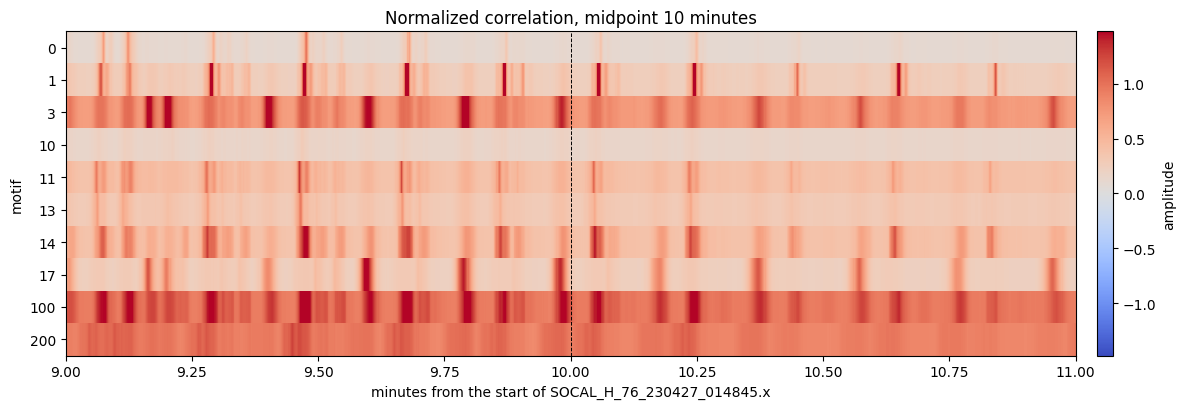

In [4]:
center_min = 10.0
half_min = 1.0
t_s = np.arange(scores.shape[1]) * sec_per_bin
mask = (t_s >= (center_min - half_min) * 60.0) & (t_s <= (center_min + half_min) * 60.0)
window = scores[:, mask]
limit = float(np.nanpercentile(np.abs(window), 99))
fig, ax = plt.subplots(figsize=(12, 4.2))
im = ax.imshow(
    window,
    aspect="auto",
    cmap="coolwarm",
    vmin=-limit,
    vmax=limit,
    interpolation="nearest",
    extent=[center_min - half_min, center_min + half_min, scores.shape[0] - 0.5, -0.5],
)
ax.axvline(center_min, color="k", lw=0.7, ls="--")
ax.set_yticks(range(len(motif_ids)))
ax.set_yticklabels([str(motif_id) for motif_id in motif_ids])
ax.set_xlabel("minutes from the start of SOCAL_H_76_230427_014845.x")
ax.set_ylabel("motif")
ax.set_title("Normalized correlation, midpoint 10 minutes")
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02, label="amplitude")
fig.tight_layout()
plt.show()


## Motif responses from 9 to 11 minutes

Each row is one motif score over the same two minutes, centered at 10.00.


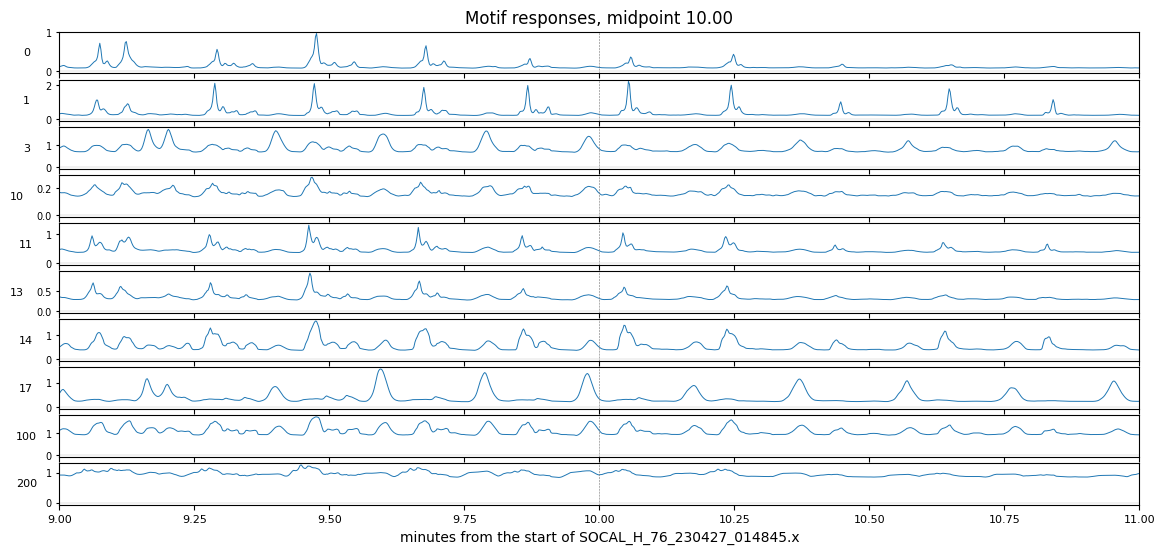

In [5]:
center_min = 10.0
half_min = 1.0
t_s = np.arange(scores.shape[1]) * sec_per_bin
mask = (t_s >= (center_min - half_min) * 60.0) & (t_s <= (center_min + half_min) * 60.0)
t_min = t_s[mask] / 60.0
n = scores.shape[0]
fig, axes = plt.subplots(n, 1, figsize=(12, 0.55 * n), sharex=True)
for i, ax in enumerate(np.atleast_1d(axes)):
    ax.plot(t_min, scores[i, mask], color="C0", lw=0.7)
    ax.axvline(center_min, color="0.45", lw=0.4, ls="--")
    ax.axhline(0, color="0.75", lw=0.3)
    ax.set_ylabel(str(motif_ids[i]), fontsize=8, rotation=0, labelpad=14, va="center")
    ax.tick_params(axis="y", labelsize=7, length=2)
    ax.tick_params(axis="x", labelsize=8)
axes[-1].set_xlim(center_min - half_min, center_min + half_min)
axes[-1].set_xlabel("minutes from the start of SOCAL_H_76_230427_014845.x")
axes[0].set_title("Motif responses, midpoint 10.00")
fig.subplots_adjust(hspace=0.15, left=0.08, right=0.98, top=0.94, bottom=0.08)
plt.show()


## Spectrogram and placements, 19 to 21 minutes

The spectrogram is the cube root of the whitened STFT from 0 to 500 Hz. Each bar is one placement of dictionary 1: motif on the vertical axis, time span equal to that motif's width, color equal to the placement amplitude.


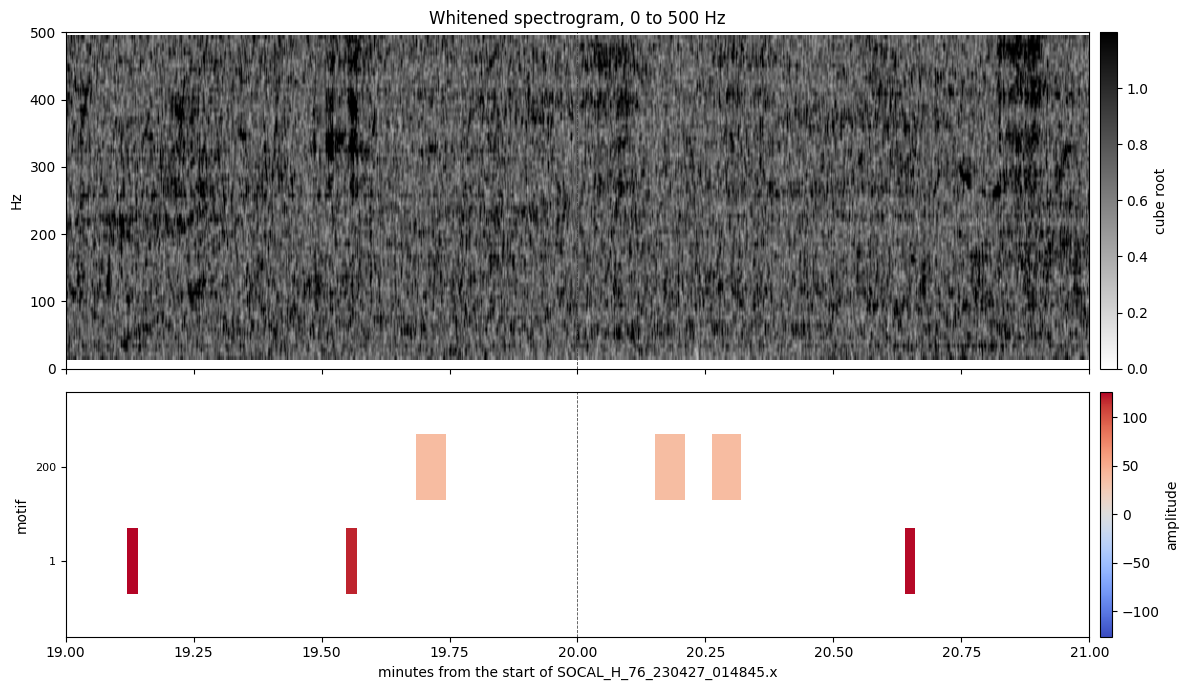

6 detections of 2 motifs in this window


In [6]:
lo_s, hi_s = 19 * 60.0, 21 * 60.0
lo = int(np.floor(lo_s / sec_per_bin))
hi = int(np.ceil(hi_s / sec_per_bin))
parts = []
for window in windows:
    a = offset[window.window_id]
    b = a + int(window.data.shape[1])
    if b <= lo or a >= hi:
        continue
    sl = window.data[:, max(0, lo - a) : min(window.data.shape[1], hi - a)]
    parts.append(np.asarray(sl, dtype=np.float64))
chunk = np.concatenate(parts, axis=1)
freq_axis = np.linspace(0.0, float(windows[0].sample_freq) / 2.0, int(windows[0].fftl) // 2)
i0 = int(np.argmin(np.abs(freq_axis - start_freq)))
freqs = freq_axis[i0 : i0 + chunk.shape[0]]
band = np.flatnonzero(freqs <= 500.0)
chunk = chunk[int(band[0]) : int(band[-1]) + 1]
f_lo = float(freqs[int(band[0])])
f_hi = float(freqs[int(band[-1])])
shown = display_from_spwhiten(chunk)
t_left = lo * sec_per_bin / 60.0
t_right = (lo + chunk.shape[1]) * sec_per_bin / 60.0

conn = sqlite3.connect(f"file:{CATALOG}?mode=ro", uri=True)
detections = conn.execute(
    """
    SELECT m.t_start, m.amplitude, t.template_id, t.width, m.window_id
    FROM matchings m
    JOIN templates t ON t.template_pk = m.template_pk
    WHERE m.dictionary_id = ?
    """,
    (DICTIONARY_ID,),
).fetchall()
conn.close()

kept = []
for t_start, amplitude, template_id, width, window_id in detections:
    if window_id not in offset:
        continue
    g0 = offset[window_id] + int(t_start)
    g1 = g0 + int(width)
    start_min = g0 * sec_per_bin / 60.0
    end_min = g1 * sec_per_bin / 60.0
    if end_min < 19.0 or start_min > 21.0:
        continue
    kept.append((int(template_id), start_min, end_min, float(amplitude)))

present = sorted({row[0] for row in kept})
y_of = {motif_id: i for i, motif_id in enumerate(present)}
limit = max((abs(row[3]) for row in kept), default=1.0)
norm = plt.Normalize(vmin=-limit, vmax=limit)
cmap = plt.cm.coolwarm

fig, (ax_spec, ax_det) = plt.subplots(
    2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [2.2, 1.6]}
)
contrast_hi = float(np.percentile(shown, 98))
im = ax_spec.imshow(
    shown,
    origin="lower",
    aspect="auto",
    cmap="gray_r",
    vmin=0.0,
    vmax=contrast_hi,
    extent=[t_left, t_right, f_lo, f_hi],
)
ax_spec.set_ylim(0.0, 500.0)
ax_spec.axvline(20.0, color="0.25", lw=0.6, ls="--")
ax_spec.set_ylabel("Hz")
ax_spec.set_title("Whitened spectrogram, 0 to 500 Hz")
fig.colorbar(im, ax=ax_spec, fraction=0.02, pad=0.01, label="cube root")

for motif_id, start_min, end_min, amplitude in kept:
    ax_det.barh(
        y_of[motif_id],
        max(0.0, min(21.0, end_min) - max(19.0, start_min)),
        left=max(19.0, start_min),
        height=0.7,
        color=cmap(norm(amplitude)),
        align="center",
    )
ax_det.axvline(20.0, color="0.3", lw=0.6, ls="--")
ax_det.set_yticks(range(len(present)))
ax_det.set_yticklabels([str(motif_id) for motif_id in present], fontsize=8)
ax_det.set_ylabel("motif")
ax_det.set_xlabel("minutes from the start of SOCAL_H_76_230427_014845.x")
ax_det.set_xlim(19.0, 21.0)
ax_det.set_ylim(-0.8, max(len(present) - 0.2, 0.8))
fig.colorbar(
    plt.cm.ScalarMappable(norm=norm, cmap=cmap),
    ax=ax_det,
    fraction=0.02,
    pad=0.01,
    label="amplitude",
)
fig.tight_layout()
plt.show()
print(f"{len(kept)} detections of {len(present)} motifs in this window")


## Specificity

Coverage, over-coverage, and the 90th percentile of each motif's specificity distribution. The dot product uses the motif mean, then the sequence is shifted and scaled by a one-minute Gaussian. `k` is the standard deviation of the shorter smoothing Gaussian, half of each motif width.


In [7]:
from analysis.evaluation import evaluate_dictionary

result = evaluate_dictionary(DICTIONARY_ID, WAV, catalog=CATALOG)
print(result["wav"])
print(f"coverage {result['coverage']:.4f}  ({result['n_bins_covered']} / {result['n_bins_total']} columns)")
print(f"over-coverage {result['over_coverage']:.4f}  (placed length {result['placed_length']})")
percentiles = result["specificity_p90"]
shifts = result["k"]
distributions = result["specificity"]
for motif_id in motif_ids:
    print(
        f"motif {motif_id:3d}  k={shifts[motif_id]:.0f}  "
        f"p90={percentiles[motif_id]:.4f}  n={len(distributions[motif_id])}"
    )


/home/yfreund/whale_processing/LeiData/SOCAL_H_76_230427_014845.x.wav
coverage 0.1875  (3425 / 18270 columns)
over-coverage 1.0000  (placed length 3425)
motif   0  k=6  p90=3.2422  n=2059
motif   1  k=5  p90=3.0648  n=1987
motif   3  k=6  p90=2.9129  n=1895
motif  10  k=7  p90=2.7733  n=2164
motif  11  k=7  p90=3.4526  n=2027
motif  13  k=8  p90=3.7355  n=1837
motif  14  k=5  p90=2.4579  n=1652
motif  17  k=9  p90=2.8699  n=1531
motif 100  k=5  p90=2.3136  n=1957
motif 200  k=14  p90=3.6583  n=2322
